# Praktikum 7 — Imbalanced Dataset dan Feature Selection

Notebook ini mengikuti Modul Praktikum Penambangan Data Pertemuan 7. Alur kerjanya: menyiapkan lingkungan,
memuat *Stroke Prediction Dataset*, membersihkan data, menerapkan empat teknik penyeimbangan kelas
(*Random Under-Sampling*, *Random Over-Sampling*, SMOTE, ADASYN), lalu melanjutkan ke seleksi fitur
(*filter*, *wrapper*, *embedded*) pada *Heart Attack Dataset*, dan menutup dengan komparasi *balancing*
pada dataset kedua.

## 1. Persiapan Lingkungan

In [1]:
%pip install -q imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


Pustaka yang dipakai mencakup manipulasi data tabular, visualisasi, pemodelan pohon keputusan,
seleksi fitur, metrik evaluasi, dan empat penyeimbang kelas dari `imbalanced-learn`.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.feature_selection import RFE, f_classif
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 130)

## 2. Memuat Stroke Prediction Dataset

In [3]:
URL_STROKE = ("https://raw.githubusercontent.com/ganjar87/"
               "data_science_practice/main/healthcare-dataset-stroke-data.csv")
stroke = pd.read_csv(URL_STROKE)
print("Dimensi dataset:", stroke.shape)
stroke.head()

Dimensi dataset: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


Pemeriksaan struktur kolom memastikan tipe data setiap fitur sudah sesuai sebelum analisis dijalankan.

In [4]:
stroke.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


Selanjutnya saya memeriksa nilai kosong pada setiap kolom.

In [5]:
stroke.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

## 3. Distribusi Kelas Target

Proporsi kelas target dihitung dan digambarkan sebagai diagram lingkaran untuk melihat seberapa jauh
ketidakseimbangan yang terjadi.

        jumlah  persen
stroke                
0         4861   95.13
1          249    4.87


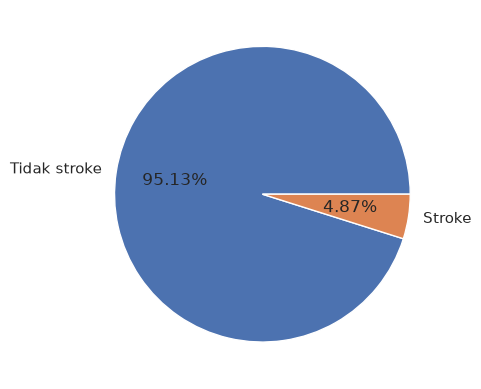

In [6]:
jumlah = stroke["stroke"].value_counts()
proporsi = stroke["stroke"].value_counts(normalize=True).mul(100).round(2)
print(pd.DataFrame({"jumlah": jumlah, "persen": proporsi}))

jumlah.plot(kind="pie", autopct="%.2f%%", labels=["Tidak stroke", "Stroke"], ylabel="")
plt.show()

## 4. Data Cleaning

Kolom `bmi` memiliki 201 nilai kosong. Karena BMI bertipe numerik kontinu dengan sebaran yang stabil,
nilai kosong diisi dengan rata-rata kolom tersebut.

In [7]:
stroke["bmi"] = stroke["bmi"].fillna(stroke["bmi"].mean())
stroke.isnull().sum()

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

## 5. Random Under-Sampling

Fitur dipisahkan dari label, fitur kategorikal dikodekan dengan `LabelEncoder`, lalu data dibagi menjadi
set pelatihan dan pengujian dengan rasio 75:25. Penyeimbangan hanya diterapkan pada set pelatihan agar set
pengujian tetap mencerminkan sebaran asli.

In [8]:
def siapkan_data(frame):
    fitur = frame.drop(columns=["id", "stroke"])
    target = frame["stroke"]
    encoder = LabelEncoder()
    for kolom in fitur.select_dtypes(exclude="number").columns:
        fitur[kolom] = encoder.fit_transform(fitur[kolom])
    return train_test_split(fitur.astype(float), target, test_size=0.25, random_state=42)


X_train, X_test, y_train, y_test = siapkan_data(stroke)
print("Latih:", X_train.shape, "| Uji:", X_test.shape)
print(pd.Series(y_train).value_counts())

Latih: (3832, 10) | Uji: (1278, 10)
stroke
0    3663
1     169
Name: count, dtype: int64


`RandomUnderSampler` memangkas sampel kelas mayoritas secara acak sampai jumlahnya setara dengan kelas minoritas.

In [9]:
under = RandomUnderSampler(random_state=0)
X_under, y_under = under.fit_resample(X_train, y_train)
print("Sebelum:", pd.Series(y_train).value_counts().to_dict())
print("Sesudah:", pd.Series(y_under).value_counts().to_dict())

Sebelum: {0: 3663, 1: 169}
Sesudah: {0: 169, 1: 169}


## 6. Fungsi Bantu Visualisasi

Dua fungsi berikut dipakai berulang pada setiap teknik penyeimbangan, satu untuk membandingkan jumlah
sampel per kelas dan satu untuk melihat sebaran titik data pada ruang fitur.

In [10]:
def bandingkan_distribusi(sebelum, sesudah, judul):
    tabel = pd.DataFrame({
        "Sebelum": pd.Series(sebelum).value_counts().sort_index(),
        "Sesudah": pd.Series(sesudah).value_counts().sort_index(),
    })
    tabel.plot(kind="bar", figsize=(6, 4), rot=0)
    plt.title(judul)
    plt.xlabel("Kelas stroke")
    plt.ylabel("Jumlah sampel")
    plt.show()


def sebar_data(fitur, target, judul):
    sns.scatterplot(data=fitur, x="avg_glucose_level", y="bmi",
                    hue=target, palette="Set1", alpha=0.6)
    plt.title(judul)
    plt.show()

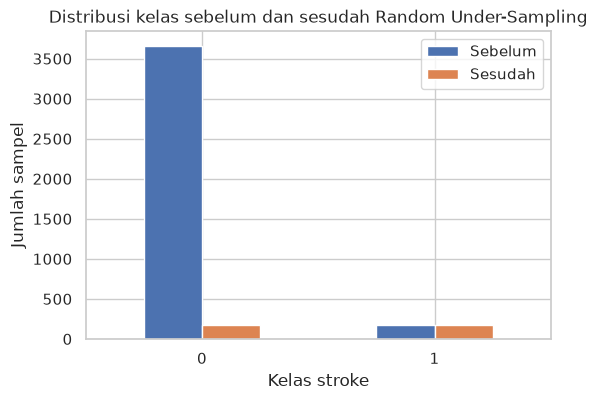

In [11]:
bandingkan_distribusi(y_train, y_under, "Distribusi kelas sebelum dan sesudah Random Under-Sampling")

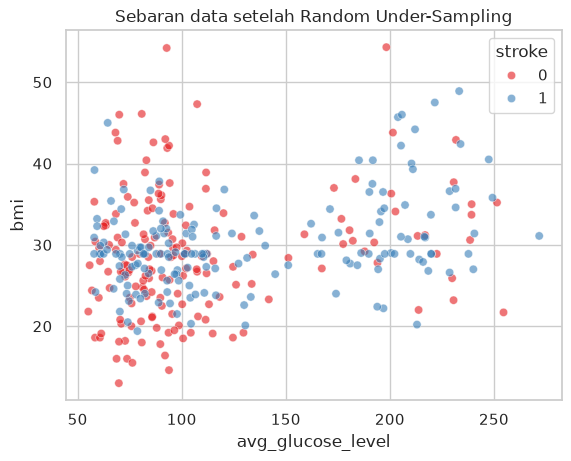

In [12]:
sebar_data(X_under, y_under, "Sebaran data setelah Random Under-Sampling")

## 7. Random Over-Sampling

`RandomOverSampler` menduplikasi sampel kelas minoritas secara acak sampai jumlahnya menyamai kelas mayoritas.

In [13]:
over = RandomOverSampler(random_state=0)
X_over, y_over = over.fit_resample(X_train, y_train)
print("Sebelum:", pd.Series(y_train).value_counts().to_dict())
print("Sesudah:", pd.Series(y_over).value_counts().to_dict())

Sebelum: {0: 3663, 1: 169}
Sesudah: {0: 3663, 1: 3663}


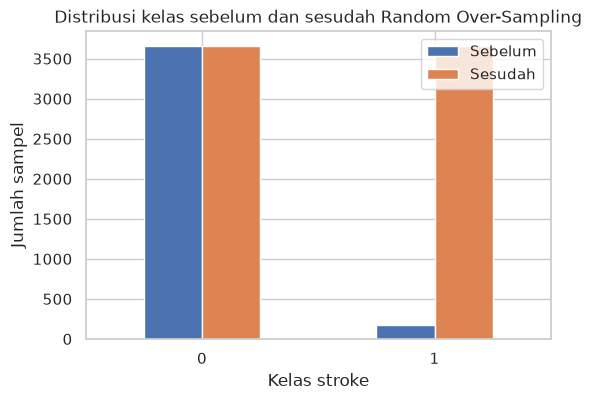

In [14]:
bandingkan_distribusi(y_train, y_over, "Distribusi kelas sebelum dan sesudah Random Over-Sampling")

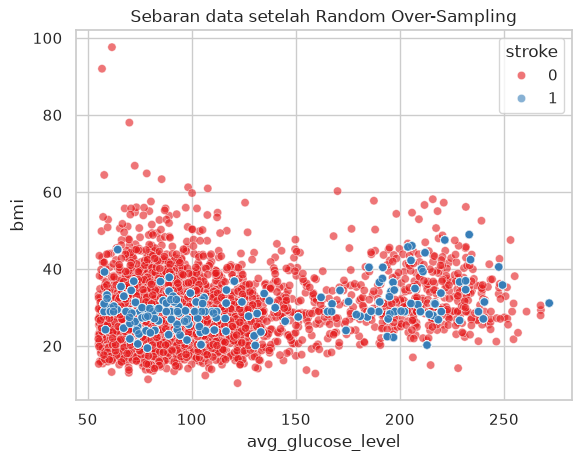

In [15]:
sebar_data(X_over, y_over, "Sebaran data setelah Random Over-Sampling")

## 8. SMOTE

SMOTE tidak menduplikasi data. Untuk setiap sampel minoritas, SMOTE mencari $k$ tetangga terdekat lalu
membuat sampel sintetis di sepanjang garis yang menghubungkan sampel tersebut dengan salah satu tetangganya.

In [16]:
smote = SMOTE(random_state=0)
X_smote, y_smote = smote.fit_resample(X_train, y_train)
print("Sebelum:", pd.Series(y_train).value_counts().to_dict())
print("Sesudah:", pd.Series(y_smote).value_counts().to_dict())

Sebelum: {0: 3663, 1: 169}
Sesudah: {0: 3663, 1: 3663}


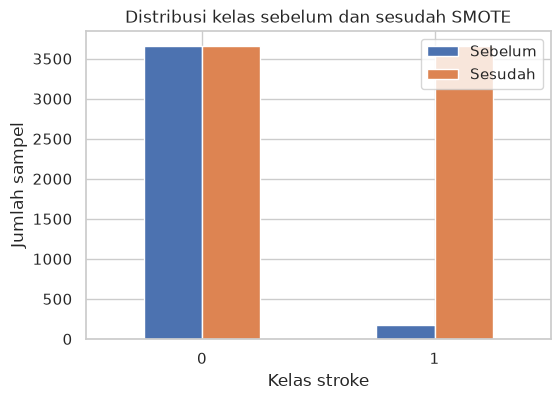

In [17]:
bandingkan_distribusi(y_train, y_smote, "Distribusi kelas sebelum dan sesudah SMOTE")

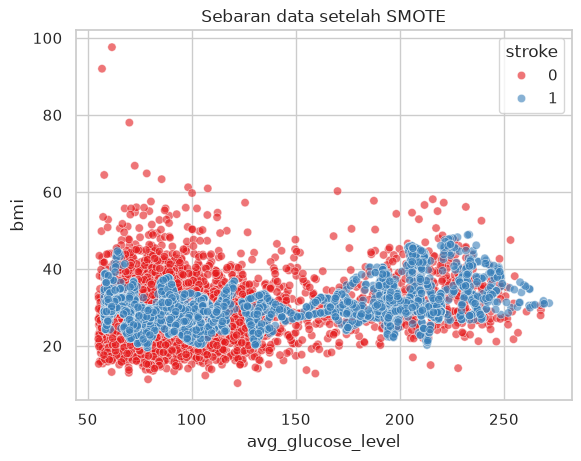

In [18]:
sebar_data(X_smote, y_smote, "Sebaran data setelah SMOTE")

## 9. ADASYN

ADASYN memberi bobot pada setiap sampel minoritas menurut tingkat kesulitan klasifikasinya. Sampel yang
berada dekat batas keputusan memperoleh porsi sampel sintetis lebih banyak dibanding sampel di area mudah.

In [19]:
adasyn = ADASYN(random_state=0)
X_adasyn, y_adasyn = adasyn.fit_resample(X_train, y_train)
print("Sebelum:", pd.Series(y_train).value_counts().to_dict())
print("Sesudah:", pd.Series(y_adasyn).value_counts().to_dict())

Sebelum: {0: 3663, 1: 169}
Sesudah: {1: 3676, 0: 3663}


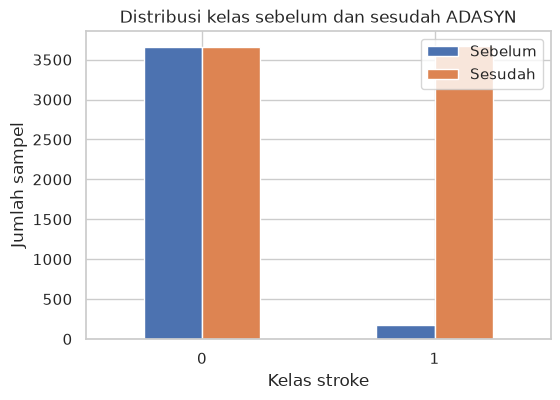

In [20]:
bandingkan_distribusi(y_train, y_adasyn, "Distribusi kelas sebelum dan sesudah ADASYN")

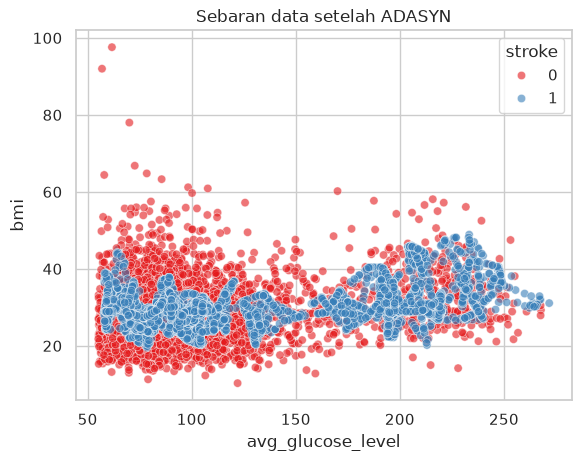

In [21]:
sebar_data(X_adasyn, y_adasyn, "Sebaran data setelah ADASYN")

## 10. Feature Selection — Filter Method dengan ANOVA

Bagian ini memakai *Heart Attack Analysis and Prediction Dataset* yang memiliki 13 fitur dan satu label `output`.
Uji ANOVA (`f_classif`) mengukur seberapa besar perbedaan rata-rata tiap fitur antar-kelas, lalu peringkat skor
$F$ dipakai untuk memilih delapan fitur teratas.

In [22]:
URL_HEART = ("https://raw.githubusercontent.com/ganjar87/"
              "data_science_practice/main/heart.csv")
jantung = pd.read_csv(URL_HEART)
print("Dimensi dataset:", jantung.shape)
print(jantung["output"].value_counts())
jantung.head()

Dimensi dataset: (303, 14)
output
1    165
0    138
Name: count, dtype: int64


,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [23]:
X_jantung = jantung.drop(columns="output")
y_jantung = jantung["output"]

skor_f, nilai_p = f_classif(X_jantung, y_jantung)
anova = (pd.DataFrame({"F": skor_f, "p_value": nilai_p}, index=X_jantung.columns)
         .sort_values("F", ascending=False).round(4))
anova

,F,p_value
exng,70.9524,0.0000
cp,69.7723,0.0000
oldpeak,68.5514,0.0000
thalachh,65.1201,0.0000
caa,54.5598,0.0000
slp,40.9021,0.0000
thall,40.4077,0.0000
sex,25.7922,0.0000
age,16.1167,0.0001
trtbps,6.4582,0.0115


In [24]:
fitur_anova = anova.index[:8].tolist()
print("Fitur terpilih (ANOVA):", fitur_anova)

Fitur terpilih (ANOVA): ['exng', 'cp', 'oldpeak', 'thalachh', 'caa', 'slp', 'thall', 'sex']


## 11. Feature Selection — Wrapper Method dengan RFE

*Recursive Feature Elimination* melatih model, membuang fitur dengan bobot terkecil, lalu mengulang prosesnya
sampai jumlah fitur yang tersisa sesuai target.

In [25]:
rfe = RFE(estimator=DecisionTreeClassifier(random_state=42), n_features_to_select=5)
rfe.fit(X_jantung, y_jantung)
fitur_rfe = X_jantung.columns[rfe.support_].tolist()
print("Fitur terpilih (RFE):", fitur_rfe)

Fitur terpilih (RFE): ['age', 'cp', 'thalachh', 'caa', 'thall']


## 12. Feature Selection — Embedded Method dengan ExtraTree

*ExtraTreesClassifier* menghitung *feature importance* selama pelatihan model, sehingga seleksi berjalan menyatu
dengan proses belajar. Enam fitur dengan kepentingan tertinggi diambil sebagai subset terpilih.

In [26]:
extra = ExtraTreesClassifier(random_state=42)
extra.fit(X_jantung, y_jantung)
kepentingan = (pd.Series(extra.feature_importances_, index=X_jantung.columns)
               .sort_values(ascending=False).round(4))
print(kepentingan)

fitur_extra = kepentingan.index[:6].tolist()
print("Fitur terpilih (ExtraTree):", fitur_extra)

caa         0.1231
cp          0.1191
exng        0.1030
thall       0.0992
oldpeak     0.0923
thalachh    0.0837
age         0.0730
slp         0.0708
chol        0.0628
trtbps      0.0606
sex         0.0569
restecg     0.0355
fbs         0.0200
dtype: float64
Fitur terpilih (ExtraTree): ['caa', 'cp', 'exng', 'thall', 'oldpeak', 'thalachh']


## 13. Komparasi Tiga Metode Seleksi Fitur

Setiap subset fitur diuji dengan `DecisionTreeClassifier` pada pembagian data yang sama, sehingga
perbedaan akurasi hanya berasal dari pilihan fiturnya.

In [27]:
def akurasi_pohon(kolom):
    X_latih, X_uji, y_latih, y_uji = train_test_split(
        X_jantung[kolom], y_jantung, test_size=0.2, random_state=42)
    model = DecisionTreeClassifier(random_state=42).fit(X_latih, y_latih)
    return (round(accuracy_score(y_latih, model.predict(X_latih)), 3),
            round(accuracy_score(y_uji, model.predict(X_uji)), 3))


skenario = {
    "Tanpa seleksi": X_jantung.columns.tolist(),
    "Filter ANOVA": fitur_anova,
    "Wrapper RFE": fitur_rfe,
    "Embedded ExtraTree": fitur_extra,
}

hasil_seleksi = pd.DataFrame(
    [(nama, len(kolom), *akurasi_pohon(kolom)) for nama, kolom in skenario.items()],
    columns=["Metode", "Jumlah fitur", "Akurasi latih", "Akurasi uji"])
hasil_seleksi

,Metode,Jumlah fitur,Akurasi latih,Akurasi uji
0,Tanpa seleksi,13,1.000,0.754
1,Filter ANOVA,8,1.000,0.820
2,Wrapper RFE,5,1.000,0.820
3,Embedded ExtraTree,6,0.996,0.770


## 14. Pemeriksaan Overfitting dan Pemangkasan Pohon

Pohon keputusan tanpa batas kedalaman mudah menghafal data latih. Perbandingan akurasi latih dan uji
berikut menunjukkan gejalanya, lalu pemangkasan kedalaman dipakai sebagai penanganannya.

In [28]:
X_latih, X_uji, y_latih, y_uji = train_test_split(
    X_jantung[fitur_extra], y_jantung, test_size=0.2, random_state=42)

pohon_penuh = DecisionTreeClassifier(random_state=42).fit(X_latih, y_latih)
pohon_pangkas = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_latih, y_latih)

pd.DataFrame({
    "Model": ["Pohon penuh", "Pohon dipangkas (max_depth=3)"],
    "Kedalaman": [pohon_penuh.get_depth(), pohon_pangkas.get_depth()],
    "Jumlah daun": [pohon_penuh.get_n_leaves(), pohon_pangkas.get_n_leaves()],
    "Akurasi latih": [round(accuracy_score(y_latih, pohon_penuh.predict(X_latih)), 3),
                      round(accuracy_score(y_latih, pohon_pangkas.predict(X_latih)), 3)],
    "Akurasi uji": [round(accuracy_score(y_uji, pohon_penuh.predict(X_uji)), 3),
                    round(accuracy_score(y_uji, pohon_pangkas.predict(X_uji)), 3)],
})

,Model,Kedalaman,Jumlah daun,Akurasi latih,Akurasi uji
0,Pohon penuh,11,56,0.996,0.770
1,Pohon dipangkas (max_depth=3),3,8,0.843,0.787


## 15. Tugas 1 — Eksplorasi Dataset Stroke

Tugas pertama meminta penjelasan tujuan dataset dan arti setiap fitur. Ringkasan berikut merangkum tipe data,
jumlah nilai unik, dan contoh nilai tiap kolom sebagai bahan penjelasan.

In [29]:
pd.DataFrame({
    "Tipe data": stroke.dtypes.astype(str),
    "Nilai unik": stroke.nunique(),
    "Nilai hilang": stroke.isnull().sum(),
    "Contoh": [stroke[k].dropna().iloc[0] for k in stroke.columns],
})

,Tipe data,Nilai unik,Nilai hilang,Contoh
id,int64,5110,0,9046
gender,str,3,0,Male
age,float64,104,0,67.0
hypertension,int64,2,0,0
heart_disease,int64,2,0,1
ever_married,str,2,0,Yes
work_type,str,5,0,Private
Residence_type,str,2,0,Urban
avg_glucose_level,float64,3979,0,228.69
bmi,float64,419,0,36.6


In [30]:
stroke.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.83,21161.72,67.00,17741.25,36932.00,54682.00,72940.00
age,5110.0,43.23,22.61,0.08,25.00,45.00,61.00,82.00
hypertension,5110.0,0.10,0.30,0.00,0.00,0.00,0.00,1.00
heart_disease,5110.0,0.05,0.23,0.00,0.00,0.00,0.00,1.00
avg_glucose_level,5110.0,106.15,45.28,55.12,77.24,91.88,114.09,271.74
bmi,5110.0,28.89,7.70,10.30,23.80,28.40,32.80,97.60
stroke,5110.0,0.05,0.22,0.00,0.00,0.00,0.00,1.00


## 16. Tugas 2 — Komparasi Balancing pada Dataset Kedua

Dataset kedua yang dipakai adalah *Wine Quality (red)* dari UCI. Label aslinya berupa skor ordinal 3 sampai 8,
dengan kelas 7 dan 8 hanya mencakup 217 dari 1.599 baris. Label saya ubah menjadi biner: kualitas premium
(skor $\geq 7$) sebagai kelas minoritas dan kualitas standar (skor $< 7$) sebagai kelas mayoritas.

In [31]:
URL_WINE = "https://raw.githubusercontent.com/plotly/datasets/master/winequality-red.csv"
anggur = pd.read_csv(URL_WINE)
anggur["premium"] = (anggur["quality"] >= 7).astype(int)
anggur = anggur.drop(columns="quality")

print("Dimensi dataset:", anggur.shape)
print(anggur["premium"].value_counts())
print("Rasio ketidakseimbangan:", round(1382 / 217, 2), ": 1")

Dimensi dataset: (1599, 12)
premium
0    1382
1     217
Name: count, dtype: int64
Rasio ketidakseimbangan: 6.37 : 1


Model dilatih pada set pelatihan yang sudah diseimbangkan dengan SMOTE atau ADASYN, lalu diuji pada set
pengujian asli. Dua pengklasifikasi dipakai agar pola perubahannya terlihat konsisten.

In [32]:
X_anggur = anggur.drop(columns="premium")
y_anggur = anggur["premium"]
X_latih_a, X_uji_a, y_latih_a, y_uji_a = train_test_split(
    X_anggur, y_anggur, test_size=0.25, random_state=42, stratify=y_anggur)

print("Latih:", pd.Series(y_latih_a).value_counts().to_dict())
print("Uji:", pd.Series(y_uji_a).value_counts().to_dict())

Latih: {0: 1036, 1: 163}
Uji: {0: 346, 1: 54}


In [33]:
def evaluasi(model, X_latih, y_latih, X_uji, y_uji, label):
    model.fit(X_latih, y_latih)
    prediksi = model.predict(X_uji)
    return {
        "Model": label,
        "Accuracy": round(accuracy_score(y_uji, prediksi), 4),
        "Precision": round(precision_score(y_uji, prediksi), 4),
        "Recall": round(recall_score(y_uji, prediksi), 4),
        "F1-Score": round(f1_score(y_uji, prediksi), 4),
    }


baris = []
for nama_model, pembuat in [("Decision Tree", DecisionTreeClassifier),
                            ("Random Forest", RandomForestClassifier)]:
    baris.append(evaluasi(pembuat(random_state=42), X_latih_a, y_latih_a,
                          X_uji_a, y_uji_a, f"{nama_model} tanpa balancing"))
    for nama_sampler, sampler in [("SMOTE", SMOTE(random_state=42)),
                                  ("ADASYN", ADASYN(random_state=42))]:
        X_res, y_res = sampler.fit_resample(X_latih_a, y_latih_a)
        baris.append(evaluasi(pembuat(random_state=42), X_res, y_res,
                              X_uji_a, y_uji_a, f"{nama_model} + {nama_sampler}"))

tabel_performa = pd.DataFrame(baris)
tabel_performa

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree tanpa balancing,0.8950,0.6111,0.6111,0.6111
1,Decision Tree + SMOTE,0.8775,0.5352,0.7037,0.6080
2,Decision Tree + ADASYN,0.8700,0.5132,0.7222,0.6000
3,Random Forest tanpa balancing,0.9400,0.8947,0.6296,0.7391
4,Random Forest + SMOTE,0.9025,0.6230,0.7037,0.6609
5,Random Forest + ADASYN,0.9050,0.6290,0.7222,0.6724


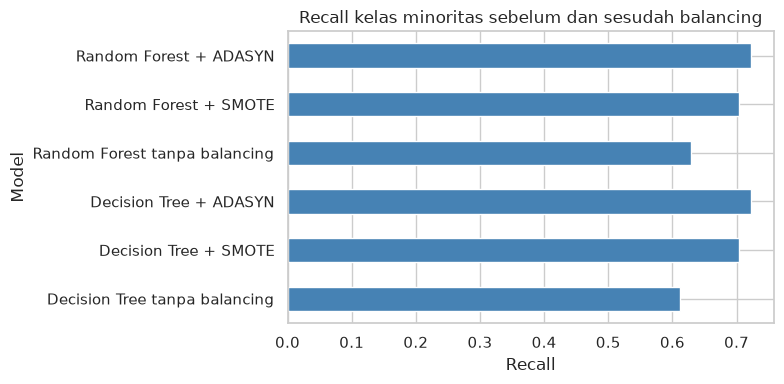

In [34]:
tabel_performa.set_index("Model")["Recall"].plot(
    kind="barh", figsize=(8, 4), color="steelblue")
plt.title("Recall kelas minoritas sebelum dan sesudah balancing")
plt.xlabel("Recall")
plt.tight_layout()
plt.show()